In [1]:
%load_ext autoreload
%autoreload 1
%aimport utility.functions
%aimport src.analysis
%aimport src.dataset
%aimport src.plots
%aimport src.simulation
import numpy as np
import utility.functions as fn
import src.simulation as sim
import src.analysis as an
import src.dataset as ds
import torch
from scipy.stats import norm
import pandas as pd
from utility.double_beta_spectrum import pdf_ratio2b

In [13]:
channels = [3, 5, 9, 11, 13, 15, 17, 19]
signal_amps = [0.00231, 0.00180, 0.00126, 0.00130, 0.00179, 0.00134, 0.001139, 0.00112]
channel_ID = [5, 9, 11, 10, 4, 2, 12, 3]

# Initialize output DataFrame
out_data = pd.DataFrame(columns=["channel_ID", "channel", "acceptance", "BI", "rp","J"])
out_data.to_csv('../outputs/BI_results_interp.csv', index=False)

# Iterate over sorted channels
for index_channel in np.argsort(channel_ID):
    channel = channels[index_channel]
    signal_amp = signal_amps[index_channel]
    
    # Load datasets and channel specifications
    data_single, data_pileup, dt_pileup, r_pileup, E_pileups = ds.create_data_sets(channel, win_length=2000, shift=-2, pos_prefix="_bis", differenciate=True)
    H_unit, S, nps, w = ds.get_channel_specs(channel, N_deriv=1)
    
    # Convert data to PyTorch tensors
    S_torch = torch.tensor(S, dtype=torch.cfloat)
    H_unit_torch = torch.tensor(H_unit, dtype=torch.cfloat)
    w_torch = torch.tensor(w, dtype=torch.cfloat)
    t_torch = torch.linspace(0, 8e-4, 100, dtype=torch.cfloat)
    r_torch = torch.linspace(0., .5, 25, dtype=torch.cfloat)
    nps_torch = torch.tensor(nps, dtype=torch.cfloat)
    signal_amp_torch = torch.tensor(signal_amp, dtype=torch.float32)
    ratio_distribution = pdf_ratio2b(r_torch.numpy())
    ratio_distribution /= np.mean(ratio_distribution)
    ratio_distribution_torch = torch.tensor(ratio_distribution, dtype=torch.cfloat)
    # Loop over acceptance levels
    for acceptance in [0.7, 0.8, 0.84, 0.87, 0.9, 0.92, 0.93, 0.94, 0.95, 0.96, 0.99]:
        N_sigma = norm.ppf(1 - (1 - acceptance) * 100 / 100)
        f1_opt, f2_opt, J_values = an.optimize_filters(S_torch, H_unit_torch, w_torch, t_torch, r_torch, nps_torch, signal_amp_torch,ratio_distribution_torch, N_sigma=N_sigma, n_trials=500)
        
        #save_filter_function 
        np.save(f"../outputs/Pileup_filter_functions/channel_{channel}/functions_eff{int(acceptance*100):d}_V2", np.array([f1_opt, f2_opt]))
        # Compute PSD and BI
        PSD_pileup,Amp_1_pileup, Amp_2_pileup= an.get_PSD_interpole(data_pileup, H_unit, f1_opt, f2_opt)
        PSD_single, Amp_1_single, Amp_2_single  = an.get_PSD_interpole(data_single, H_unit, f1_opt, f2_opt)
        cut = np.percentile(PSD_single , 100 - acceptance * 100)
        rp = np.mean(PSD_pileup  < cut)
        BI = fn.calculate_BI(rp, 0.8)
        # Append results to DataFrame
        out_data = pd.concat([out_data, pd.DataFrame([{
            "channel_ID": channel_ID[index_channel],
            "channel": channel,
            "acceptance": acceptance,
            "BI": BI,
            "rp": rp,
            "J": J_values[-1]
        }])], ignore_index=True)
        # Save results to CSV
        out_data.to_csv('../outputs/BI_results_interp_v2.csv', index=False)
        print(f"Channel {channel}, Acceptance {acceptance}: J={J_values[-1]}, 1-rp={1-rp}, BI={BI}")

Step 0: J = 0.750550
Step 100: J = 0.170934
Step 200: J = 0.146648
Step 300: J = 0.138010
Step 400: J = 0.135148
Channel 15, Acceptance 0.7: J=0.13469627499580383, 1-rp=0.16693333333333338, BI=4.403228748996755e-05
Step 0: J = 0.695811
Step 100: J = 0.209292
Step 200: J = 0.182278
Step 300: J = 0.173860
Step 400: J = 0.172079
Channel 15, Acceptance 0.8: J=0.17197543382644653, 1-rp=0.20786666666666664, BI=5.482934201027106e-05
Step 0: J = 0.807459
Step 100: J = 0.228790
Step 200: J = 0.201200
Step 300: J = 0.192565
Step 400: J = 0.190743
Channel 15, Acceptance 0.84: J=0.19059060513973236, 1-rp=0.2328, BI=6.140604948680777e-05
Step 0: J = 0.832332
Step 100: J = 0.247518
Step 200: J = 0.217870
Step 300: J = 0.208776
Step 400: J = 0.206911
Channel 15, Acceptance 0.87: J=0.20677238702774048, 1-rp=0.25160000000000005, BI=6.636495726323383e-05
Step 0: J = 0.862497
Step 100: J = 0.266685
Step 200: J = 0.236335
Step 300: J = 0.227579
Step 400: J = 0.225938
Channel 15, Acceptance 0.9: J=0.225828

In [4]:
from utility.double_beta_spectrum import pdf_ratio2b
channels = [3, 5, 9, 11, 13, 15, 17, 19]
signal_amps = [0.00231, 0.00180, 0.00126, 0.00130, 0.00179, 0.00134, 0.001139, 0.00112]
channel_ID = [5, 9, 11, 10, 4, 2, 12, 3]
index_channel = 5
channel = channels[index_channel]
signal_amp = signal_amps[index_channel]

# Load datasets and channel specifications
data_single, data_pileup, dt_pileup, r_pileup, E_pileups = ds.create_data_sets(channel, win_length=2000, shift=-2, pos_prefix="_bis", differenciate=True)
H_unit, S, nps, w = ds.get_channel_specs(channel, N_deriv=1)

# Convert data to PyTorch tensors
S_torch = torch.tensor(S, dtype=torch.cfloat)
H_unit_torch = torch.tensor(H_unit, dtype=torch.cfloat)
w_torch = torch.tensor(w, dtype=torch.cfloat)
t_torch = torch.linspace(0, 8e-4, 100, dtype=torch.cfloat)
r_torch = torch.linspace(0., .5, 25, dtype=torch.cfloat)
nps_torch = torch.tensor(nps, dtype=torch.cfloat)
signal_amp_torch = torch.tensor(signal_amp, dtype=torch.float32)
ratio_distribution = pdf_ratio2b(r_torch.numpy())
ratio_distribution /= np.mean(ratio_distribution)
ratio_distribution_torch = torch.tensor(ratio_distribution, dtype=torch.cfloat)
acceptance = 0.9
N_sigma = norm.ppf(1 - (1 - acceptance) * 100 / 100)
f1_opt, f2_opt, J_values = an.optimize_filters(S_torch, H_unit_torch, w_torch, t_torch, r_torch, nps_torch, signal_amp_torch,ratio_distribution_torch, N_sigma=N_sigma, n_trials=500)
PSD_pileup,Amp_1_pileup, Amp_2_pileup= an.get_PSD_interpole(data_pileup, H_unit, f1_opt, f2_opt)
PSD_single, Amp_1_single, Amp_2_single  = an.get_PSD_interpole(data_single, H_unit, f1_opt, f2_opt)
cut = np.percentile(PSD_single , 100 - acceptance * 100)
rp = np.mean(PSD_pileup  < cut)
BI = fn.calculate_BI(rp, 0.8)
print(J_values[-1],1-rp,BI)

Step 0: J = 0.939994
Step 50: J = 0.317800
Step 100: J = 0.273196
Step 150: J = 0.250943
Step 200: J = 0.239240
Step 250: J = 0.232280
Step 300: J = 0.228384
Step 350: J = 0.226633
Step 400: J = 0.226057
Step 450: J = 0.225929
0.22585341334342957 0.27380000000000004 7.222068878646033e-05


/local/home/mp274748/miniconda3/envs/ML_denoising/lib/python3.8/site-packages/matplotlib/axes/_axes.py:5398: ComplexWarning: Casting complex values to real discards the imaginary part
  pts[0] = start
/local/home/mp274748/miniconda3/envs/ML_denoising/lib/python3.8/site-packages/matplotlib/axes/_axes.py:5399: ComplexWarning: Casting complex values to real discards the imaginary part
  pts[N + 1] = end
/local/home/mp274748/miniconda3/envs/ML_denoising/lib/python3.8/site-packages/matplotlib/axes/_axes.py:5401: ComplexWarning: Casting complex values to real discards the imaginary part
  pts[1:N+1, 0] = indslice
/local/home/mp274748/miniconda3/envs/ML_denoising/lib/python3.8/site-packages/matplotlib/axes/_axes.py:5403: ComplexWarning: Casting complex values to real discards the imaginary part
  pts[N+2:, 0] = indslice[::-1]
/local/home/mp274748/miniconda3/envs/ML_denoising/lib/python3.8/site-packages/matplotlib/cbook/__init__.py:1340: ComplexWarning: Casting complex values to real discards 

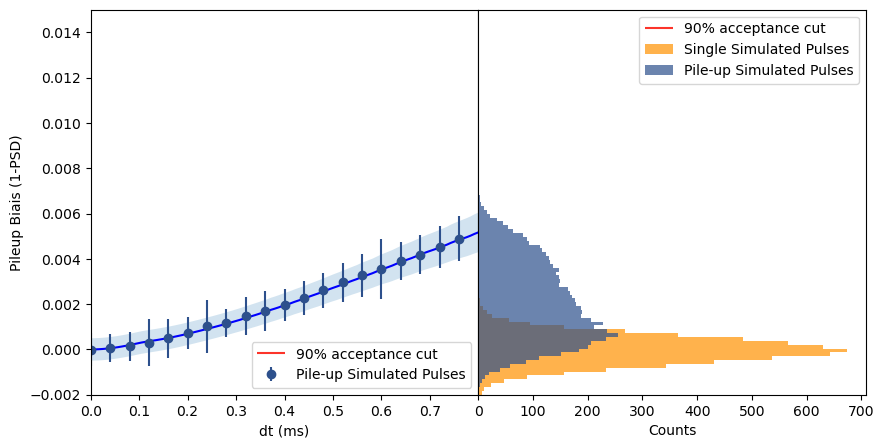

In [12]:
from src.plots import plot_biais_vs_dt
#0.17366666666666664 4.5808350204219417e-05
import matplotlib.pyplot as plt
#fig,ax = plt.subplots()
S_H_delayed, S_H, S2_over_nps = an.precompute_constants(S_torch, H_unit_torch, w_torch, t_torch, nps_torch)
f1,f2  = torch.tensor(f1_opt,dtype=torch.cfloat), torch.tensor(f2_opt,dtype=torch.cfloat)
muY, sigmaY, mu1, mu2, var1, var2, cov12= an.compute_mu_sigma(f1, f2, S_H_delayed,r_torch, S_H, S2_over_nps, signal_amp, return_all=True)
mu = torch.mean(ratio_distribution_torch[:,None]*(1-muY.real), dim = 0).numpy().real

sigma = torch.sqrt(torch.mean(ratio_distribution_torch[:,None]*sigmaY**2, dim = 0)+torch.mean(ratio_distribution_torch[:,None]*(1-muY.real)**2, dim = 0)-mu**2).numpy().real
fig,ax,ax1=plot_biais_vs_dt(PSD_single, PSD_pileup, dt_pileup,cut=cut,bins=20)
ax.fill_between(t_torch.numpy()*1e3, mu-sigma, mu+sigma, alpha=0.2)
ax.plot(t_torch.numpy()*1e3, mu, color='blue', label='Expected PSD mean')
ax.set_xlim(0,0.8)
ax.set_ylim(-0.002,0.015)
plt.show()

In [102]:
fpulses, signal_freq, noise_freq, generated_r, generated_dt = sim.simulate_frequency_pulses(S,nps,8.59898e-05,w,signal_scale = 0.001874,nsim=4000)
from torch.utils.data import TensorDataset
dataset_simu = TensorDataset(torch.from_numpy(np.fft.ifft(fpulses, axis=1).real.astype(np.float32)))
PSD_simu,Amp_1_simu, Amp_2_simu = an.get_PSD_interpole(dataset_simu, H_unit, f1_opt, f2_opt)
plt.hist2d(generated_dt*1e4,  PSD_simu, bins=100,range = [[0,8],[0.985,1.003]],norm="log")
plt.show()